## Student Placement prediction Using KNN

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
from pathlib import Path

DATA_PATH = Path('data') / 'placement.csv'

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'Dataset not found : {DATA_PATH.resolve()}'
    )

df = pd.read_csv(DATA_PATH)

In [14]:
df.head()

,student_id,age,gender,branch,cgpa,internship_count,project_count,certifications_count,coding_skills_score,communication_skills_score,soft_skills_score,hackathon_participation,placement_status
0,1,23,Male,IT,8.99,4,6,2,41,71,59,Yes,Placed
1,2,24,Female,Mechanical,8.36,4,7,5,42,64,97,No,Placed
2,3,22,Female,EEE,7.18,4,5,2,84,98,51,No,Placed
3,4,24,Female,Mechanical,6.28,0,2,4,60,100,92,No,Not Placed
4,5,24,Female,IT,5.30,3,4,1,78,61,77,No,Not Placed


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  10000 non-null  int64  
 1   age                         10000 non-null  int64  
 2   gender                      10000 non-null  object 
 3   branch                      10000 non-null  object 
 4   cgpa                        10000 non-null  float64
 5   internship_count            10000 non-null  int64  
 6   project_count               10000 non-null  int64  
 7   certifications_count        10000 non-null  int64  
 8   coding_skills_score         10000 non-null  int64  
 9   communication_skills_score  10000 non-null  int64  
 10  soft_skills_score           10000 non-null  int64  
 11  hackathon_participation     10000 non-null  object 
 12  placement_status            10000 non-null  object 
dtypes: float64(1), int64(8), object(

In [16]:
df.shape

(10000, 13)

In [17]:
df.isnull().sum()

student_id                    0
age                           0
gender                        0
branch                        0
cgpa                          0
internship_count              0
project_count                 0
certifications_count          0
coding_skills_score           0
communication_skills_score    0
soft_skills_score             0
hackathon_participation       0
placement_status              0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df['placement_status'].value_counts()

placement_status
Placed        5074
Not Placed    4926
Name: count, dtype: int64

In [20]:
df = df.drop(columns=['student_id'])

In [21]:
df.describe()

,age,cgpa,internship_count,project_count,certifications_count,coding_skills_score,communication_skills_score,soft_skills_score
count,10000.000000,10000.000000,10000.000000,10000.00000,10000.00000,10000.000000,10000.000000,10000.000000
mean,22.499900,7.520948,1.996500,4.01950,2.50910,70.026600,69.920600,70.058800
std,1.708711,1.447154,1.405591,2.00148,1.71657,17.485545,17.472986,17.667285
min,20.000000,5.000000,0.000000,1.00000,0.00000,40.000000,40.000000,40.000000
25%,21.000000,6.280000,1.000000,2.00000,1.00000,55.000000,55.000000,55.000000
50%,23.000000,7.530000,2.000000,4.00000,3.00000,70.000000,70.000000,70.000000
75%,24.000000,8.780000,3.000000,6.00000,4.00000,85.000000,85.000000,85.000000
max,25.000000,10.000000,4.000000,7.00000,5.00000,100.000000,100.000000,100.000000


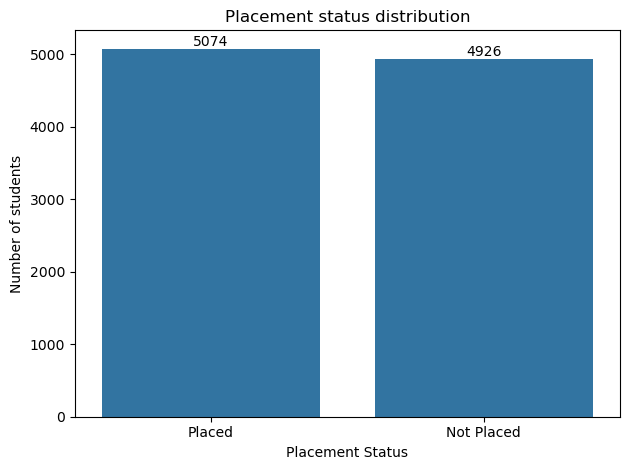

In [25]:
ax = sns.countplot(data=df,x='placement_status');
ax.set(title='Placement status distribution',
       xlabel ='Placement Status',
       ylabel = 'Number of students')
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

### EDA

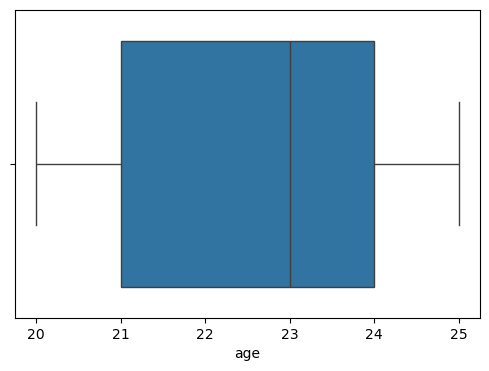

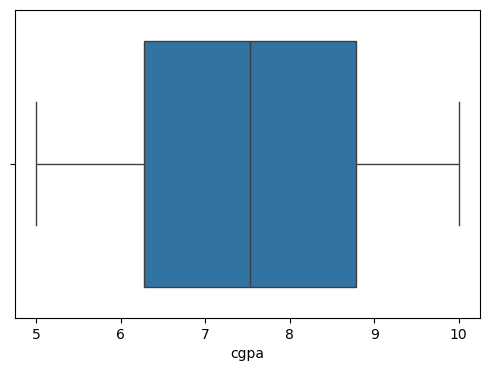

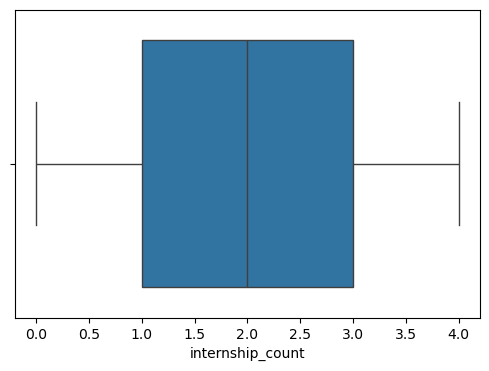

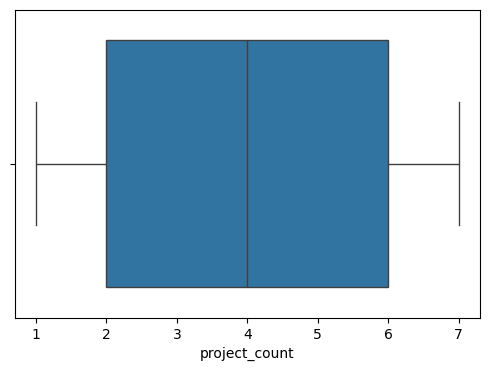

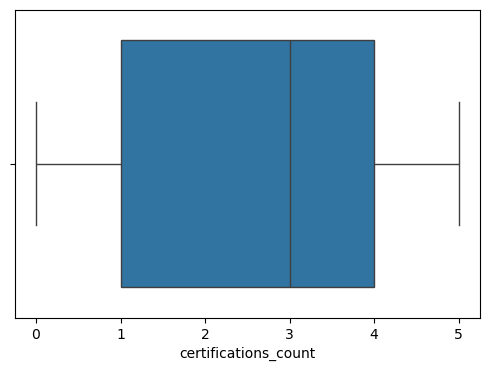

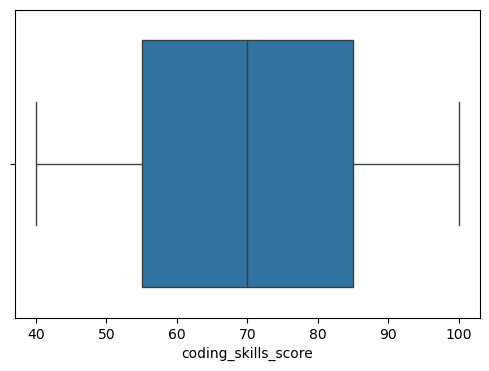

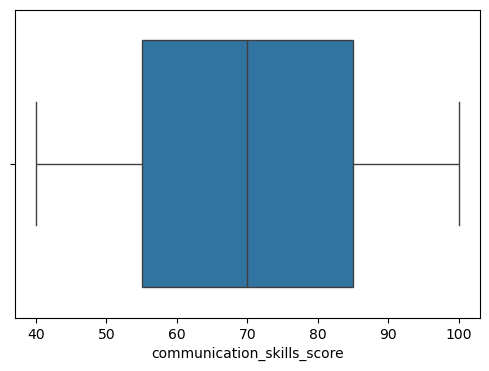

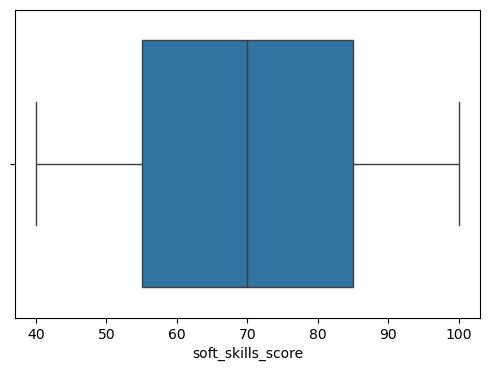

In [26]:
num = df.select_dtypes(exclude='O')
for col in num:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=df,x=col);

##### *Boxplots were used to check potential outliers most features data points were in the interquartile range*

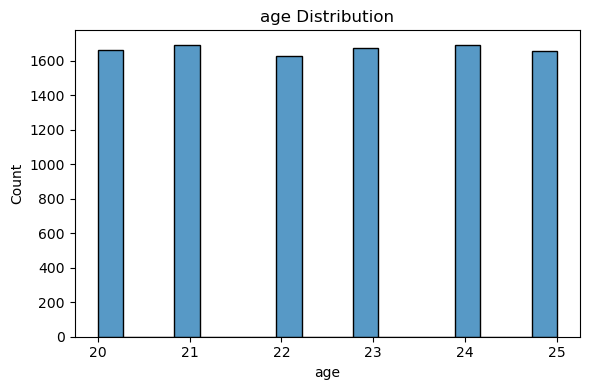

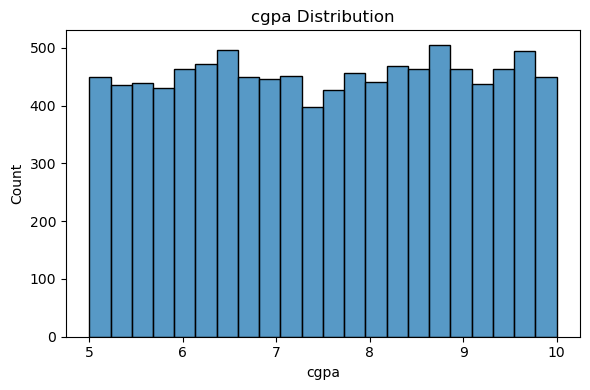

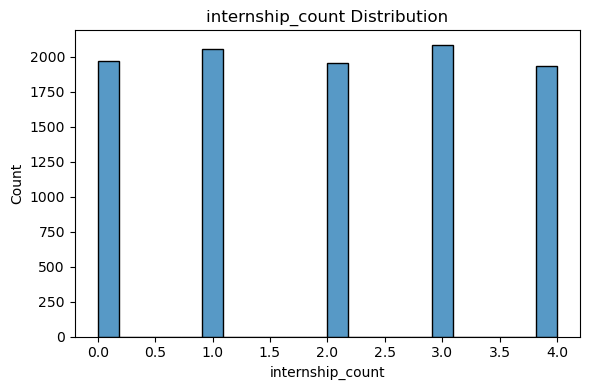

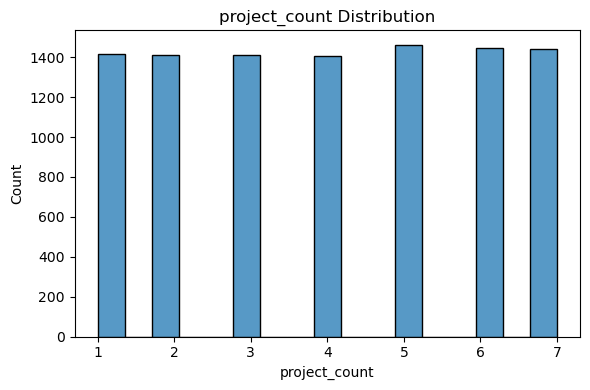

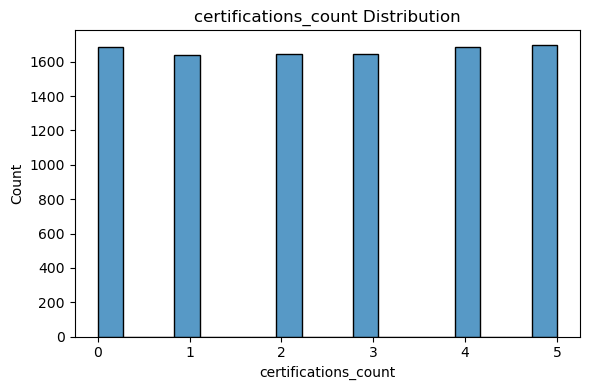

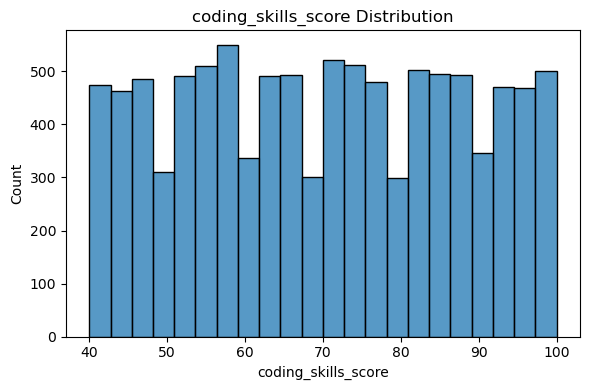

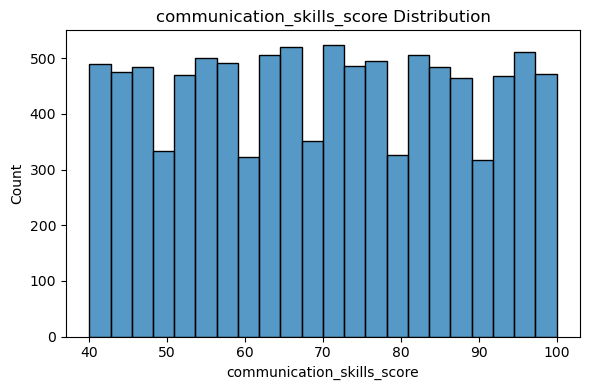

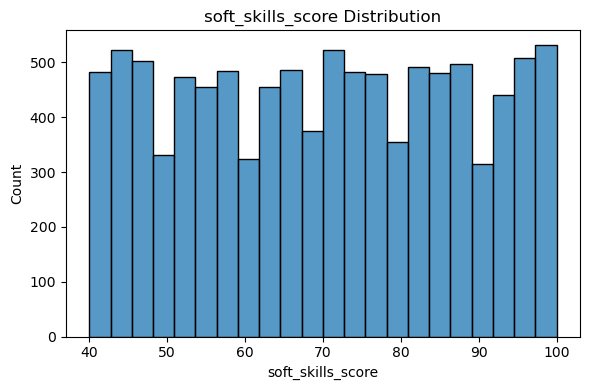

In [27]:
for cols in num:
    plt.figure(figsize=(6,4))
    ax = sns.histplot(data=df,x=cols)
    ax.set(title=f'{cols} Distribution')
    plt.tight_layout()
    plt.show()

In [28]:
num.skew()

age                          -0.002416
cgpa                         -0.014563
internship_count             -0.000705
project_count                -0.016547
certifications_count         -0.009880
coding_skills_score           0.006583
communication_skills_score    0.007170
soft_skills_score            -0.002095
dtype: float64

In [29]:
df['gender'].value_counts()

gender
Female    5016
Male      4984
Name: count, dtype: int64

In [30]:
df['gender'] = df['gender'].map({
    'Male':0,
    'Female':1
})

In [31]:
df['hackathon_participation'].value_counts()

hackathon_participation
Yes    5063
No     4937
Name: count, dtype: int64

In [32]:
df['hackathon_participation'] = df['hackathon_participation'].map({
    'Yes':1,
    'No':0
})

In [33]:
df = pd.get_dummies(data=df,columns=['branch'],drop_first=True,dtype='int')

In [34]:
df.head()

,age,gender,cgpa,internship_count,project_count,certifications_count,coding_skills_score,communication_skills_score,soft_skills_score,hackathon_participation,placement_status,branch_Civil,branch_ECE,branch_EEE,branch_IT,branch_Mechanical
0,23,0,8.99,4,6,2,41,71,59,1,Placed,0,0,0,1,0
1,24,1,8.36,4,7,5,42,64,97,0,Placed,0,0,0,0,1
2,22,1,7.18,4,5,2,84,98,51,0,Placed,0,0,1,0,0
3,24,1,6.28,0,2,4,60,100,92,0,Not Placed,0,0,0,0,1
4,24,1,5.30,3,4,1,78,61,77,0,Not Placed,0,0,0,1,0


In [35]:
df['placement_status'] = df['placement_status'].map({
    'Placed':1,
    'Not Placed':0
})

In [36]:
df.sample(n=5)

,age,gender,cgpa,internship_count,project_count,certifications_count,coding_skills_score,communication_skills_score,soft_skills_score,hackathon_participation,placement_status,branch_Civil,branch_ECE,branch_EEE,branch_IT,branch_Mechanical
9448,25,0,7.93,1,7,0,76,56,51,0,0,0,1,0,0,0
222,20,1,7.62,3,7,1,56,54,56,1,1,0,0,1,0,0
9654,20,0,6.65,2,6,1,63,63,44,1,0,0,0,0,0,1
9391,21,0,8.93,3,5,4,66,62,77,1,1,1,0,0,0,0
846,23,1,8.23,2,4,4,88,80,74,1,1,0,0,0,1,0


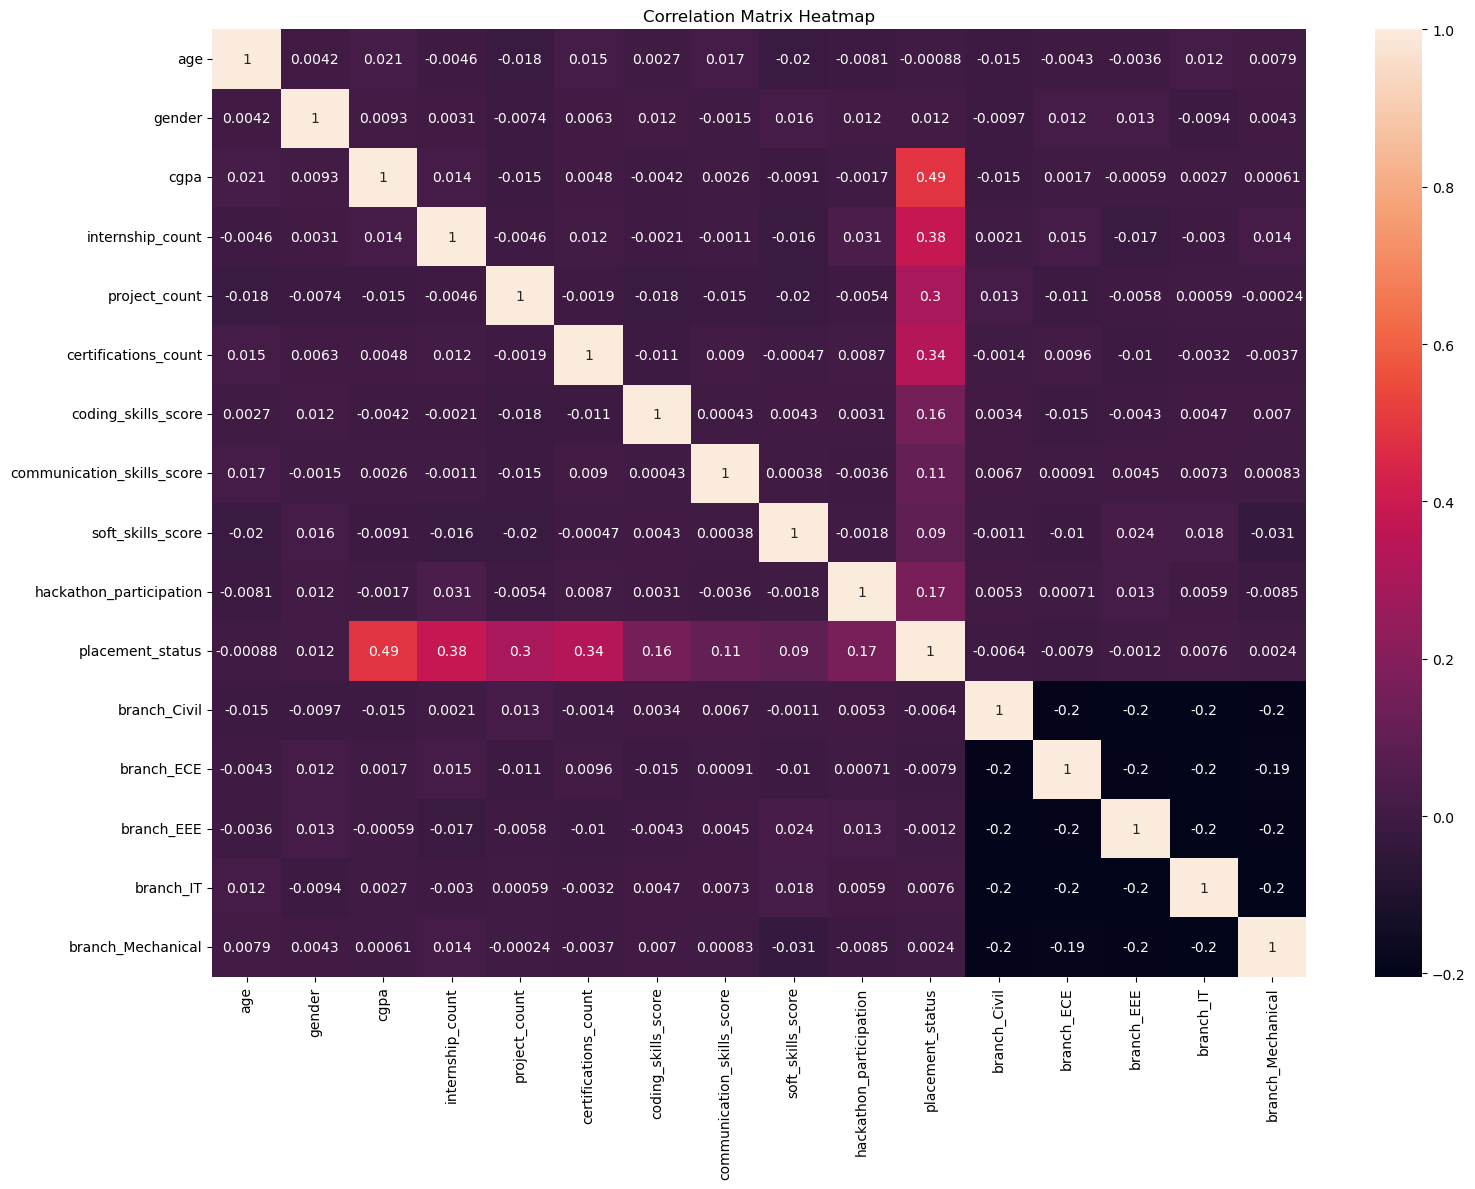

In [ ]:
plt.figure(figsize=(16,12))
ax = sns.heatmap(df.corr(),annot=True)
ax.set(title='Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()

In [52]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [41]:
X = df.drop(columns=['placement_status'])
y = df['placement_status']

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42,stratify=y)

In [43]:
X_train.shape

(7000, 15)

In [44]:
X_test.shape

(3000, 15)

In [45]:
ss = StandardScaler()
X_train_scaled = ss.fit_transform(X_train)
X_test_scaled = ss.transform(X_test)

In [46]:
model = KNeighborsClassifier(n_neighbors=5)

In [47]:
model.fit(X_train_scaled,y_train)

KNeighborsClassifier()

In [48]:
y_pred = model.predict(X_test_scaled)

In [50]:
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

acc = accuracy_score(y_test,y_pred)
mat = confusion_matrix(y_test,y_pred)
print(f'accuracy score - {np.round(acc*100,2)}%')
print('Confusion matrix \n',mat)

accuracy score - 86.13%
Confusion matrix 
 [[1277  201]
 [ 215 1307]]


In [51]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86      1478
           1       0.87      0.86      0.86      1522

    accuracy                           0.86      3000
   macro avg       0.86      0.86      0.86      3000
weighted avg       0.86      0.86      0.86      3000



- *paramter inside the model was chosen as a standard approach*
- *choose the best paramter by performing cross val or any other approach*